In [1]:
import matplotlib.pyplot as plt
import sys
sys.path.append('../../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp
import pickle as pkl
import interpax as ipx
from datetime import datetime, timedelta


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [2]:
parameterization = "cap" # imp50, imp10, drying, drying_omega10, cap

input_folder = None
input_filename = None

sim_folder = "../../output/simulation/"
sim_filename = f"simulation_{parameterization}.pkl"

save_folder = "../../docu/Figures/"
save_filename = f"{parameterization}"

In [3]:
with open(sim_folder+sim_filename, 'rb') as pickle_file:
    db = pickle.load(pickle_file)

/tmp/ipykernel_1208435/1516183429.py:2: DeprecationWarning: shape requires ndarray or scalar arguments, got <class 'list'> at position 0. In a future JAX release this will be an error.
  runoff = jnp.sum(jnp.array(db["q_runoff"]),axis=1)/jnp.shape(db["q_runoff"])[1]
/home/anne/anaconda3/envs/cryorich_AD/lib/python3.12/site-packages/matplotlib/patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212]


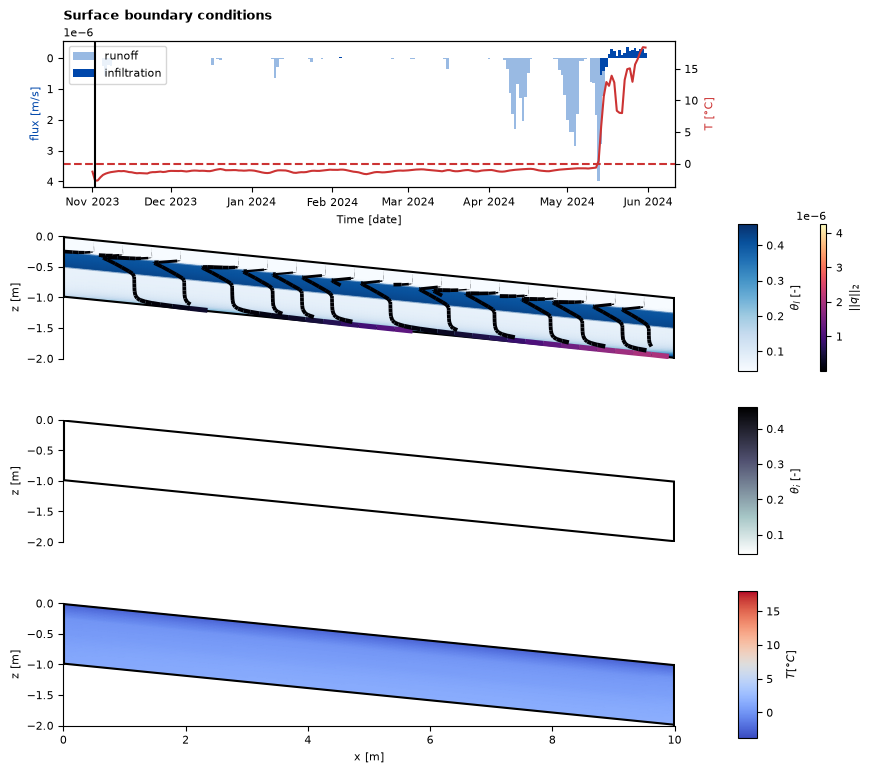

In [4]:
q_inf = db['q_inf_interp'](jnp.array(db['time_array']))
runoff = jnp.sum(jnp.array(db["q_runoff"]),axis=1)/jnp.shape(db["q_runoff"])[1]
q_inf -= runoff
T_surface = db['T_surface_interp'](jnp.array(db['time_array']))
dates = [datetime(2023, 11, 1) + timedelta(seconds=float(t)) for t in db['time_array']]
ani, fig, ax = plotting_utils.create_animation_streamlines(db['X'], db['Z'], db['theta_l_total'], db['qx_centered_array'], db['qz_centered_array'],  db['theta_i_total'],  db['T_total'],runoff,q_inf, T_surface, jnp.array(db['time_array']), dates, slope=-0.1, time_mode="date", density=1, linewidth = 4, cmaps=('Blues', 'bone_r','coolwarm'), clabels=(r'$\theta_l$ [-]', r'$\theta_i$ [-]',r'$T[°C]$'),cmap_stream="magma",arrowsize=0)


In [5]:
ani.save(save_folder+save_filename+'.mp4', writer='ffmpeg', fps=10)

/home/anne/anaconda3/envs/cryorich_AD/lib/python3.12/site-packages/matplotlib/patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist
